# Step 3 — Build EDA Notebook

**3.1 Imports and dataset path**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

DATA_DIR = Path("../data/raw")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset path:", DATA_DIR.resolve())

Dataset path: C:\Users\shivank shukla\Documents\Naresh IT\Projects\waste-classifier\data\raw


**3.2 Create dataset DataFrame**

In [2]:
records = []

for class_dir in sorted(DATA_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "image_path": str(image_path),
                "class": class_dir.name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Number of classes:", df["class"].nunique())

df.head()

Total images: 15515
Number of classes: 12


,image_path,class
0,..\data\raw\battery\battery1.jpg,battery
1,..\data\raw\battery\battery10.jpg,battery
2,..\data\raw\battery\battery100.jpg,battery
3,..\data\raw\battery\battery101.jpg,battery
4,..\data\raw\battery\battery102.jpg,battery


**3.3 Class distribution**

In [3]:
class_counts = df["class"].value_counts().sort_values(ascending=False)
class_counts

class
clothes        5325
shoes          1977
paper          1050
biological      985
battery         945
cardboard       891
plastic         865
white-glass     775
metal           769
trash           697
green-glass     629
brown-glass     607
Name: count, dtype: int64

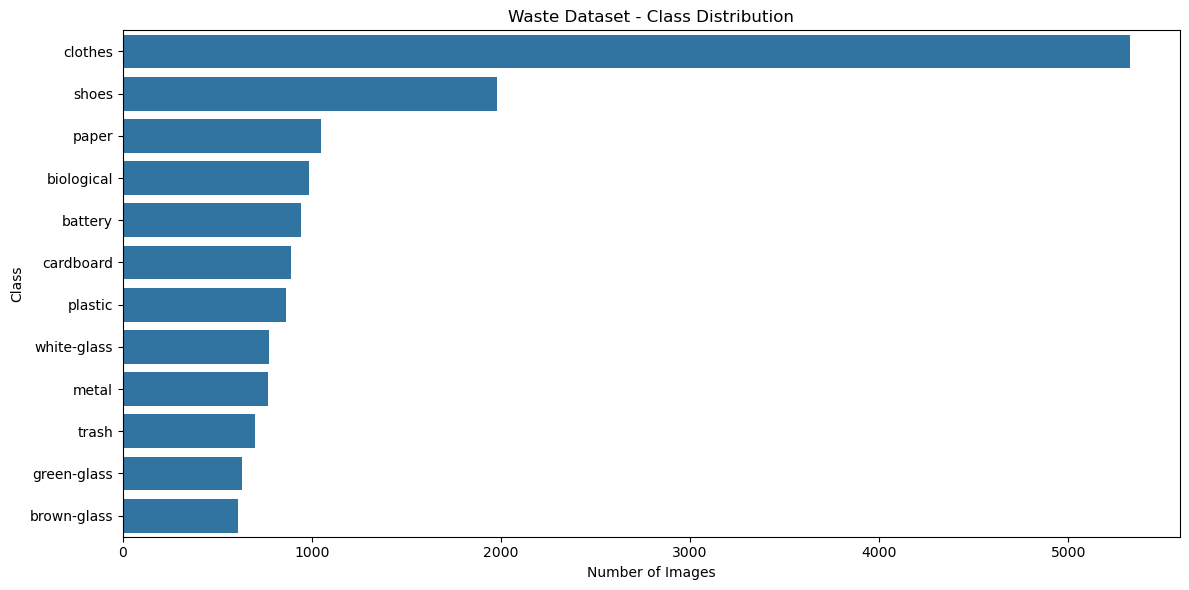

In [4]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_counts.values,
    y=class_counts.index
)

plt.title("Waste Dataset - Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**3.4 Class percentage**

In [7]:
class_percentage = (
    df["class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class_percentage

class
clothes        34.32
shoes          12.74
paper           6.77
biological      6.35
battery         6.09
cardboard       5.74
plastic         5.58
white-glass     5.00
metal           4.96
trash           4.49
green-glass     4.05
brown-glass     3.91
Name: proportion, dtype: float64

In [8]:
distribution_df = pd.DataFrame({
    "Images": class_counts,
    "Percentage": class_percentage
})

distribution_df

,Images,Percentage
class,,
clothes,5325,34.32
shoes,1977,12.74
paper,1050,6.77
biological,985,6.35
battery,945,6.09
cardboard,891,5.74
plastic,865,5.58
white-glass,775,5.00
metal,769,4.96


**3.5 Sample images from every class**

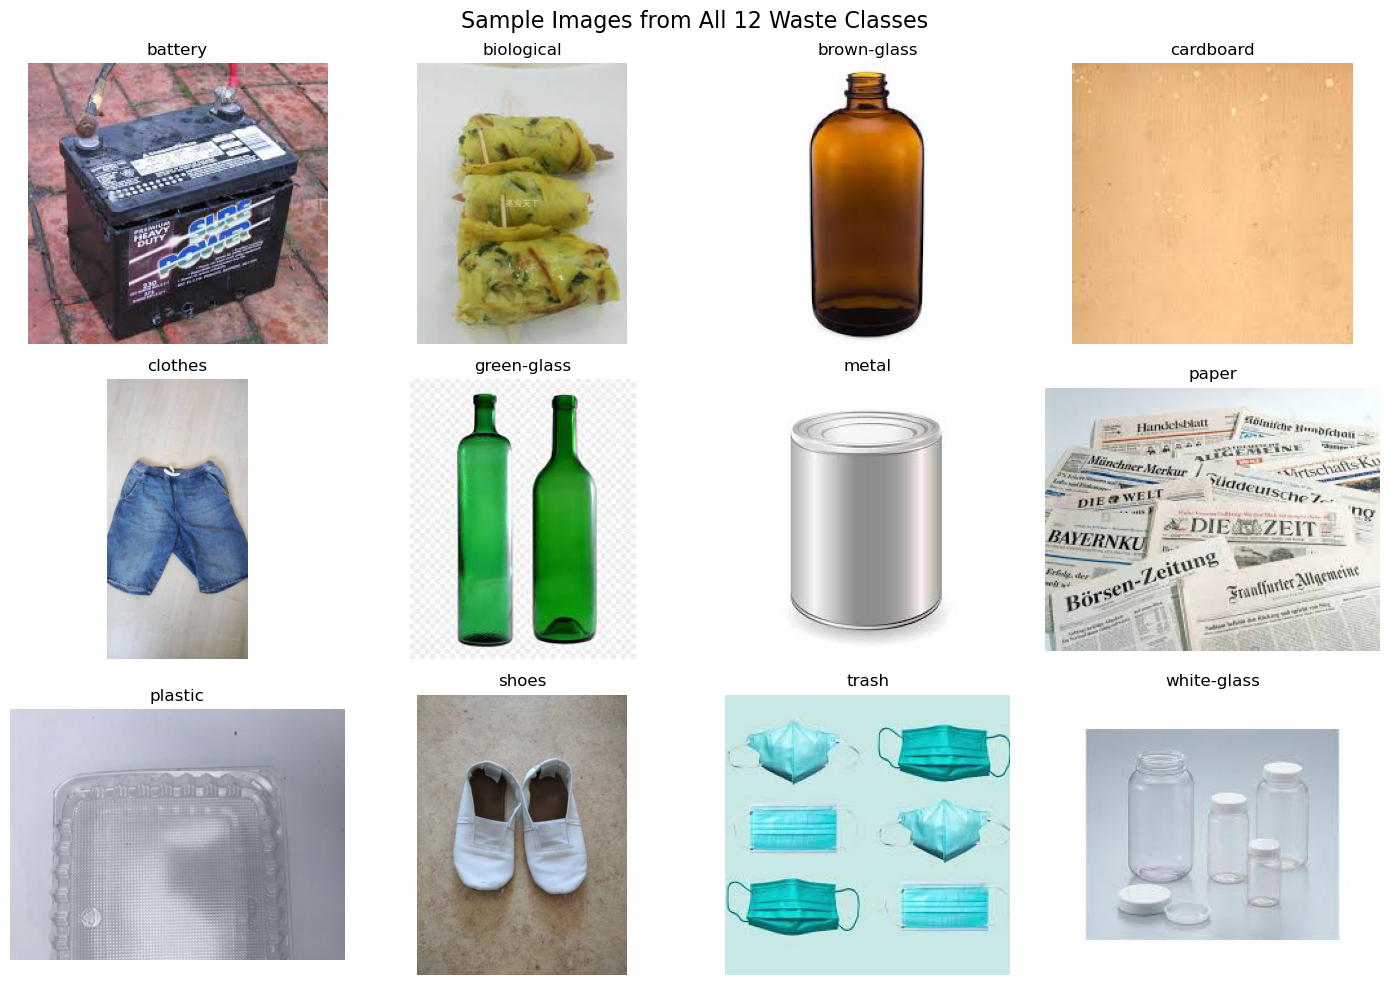

In [9]:
classes = sorted(df["class"].unique())

fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

for ax, class_name in zip(axes.flatten(), classes):

    class_images = df[df["class"] == class_name]

    image_path = class_images.sample(
        random_state=42
    ).iloc[0]["image_path"]

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle(
    "Sample Images from All 12 Waste Classes",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
dimension_records = []

for _, row in df.sample(
    min(2000, len(df)),
    random_state=42
).iterrows():

    try:
        with Image.open(row["image_path"]) as img:
            width, height = img.size

            dimension_records.append({
                "class": row["class"],
                "width": width,
                "height": height
            })

    except Exception:
        pass

dimensions_df = pd.DataFrame(dimension_records)

dimensions_df.head()

,class,width,height
0,plastic,297,170
1,biological,277,182
2,green-glass,200,200
3,clothes,400,533
4,shoes,284,178


In [11]:
dimensions_df.describe()

,width,height
count,2000.000000,2000.000000
mean,349.767500,350.913000
std,119.052145,148.116477
min,134.000000,115.000000
25%,225.000000,225.000000
50%,400.000000,384.000000
75%,400.000000,533.000000
max,847.000000,867.000000


**3.7 Check image channels**

In [12]:
channel_counts = {}

for image_path in df["image_path"].sample(
    min(2000, len(df)),
    random_state=42
):

    try:
        with Image.open(image_path) as img:

            mode = img.mode

            channel_counts[mode] = (
                channel_counts.get(mode, 0) + 1
            )

    except Exception:
        pass

channel_counts

{'RGB': 1994, 'P': 6}

## EDA Summary

- The dataset contains 15,515 images across 12 waste categories.
- The dataset contains significant class imbalance, with the clothes category having the highest number of samples.
- Image dimensions vary considerably across the dataset.
- Images will therefore be resized to a fixed input resolution during preprocessing.
- Training augmentation will be applied only to the training set.
- Validation and test images will receive deterministic preprocessing without augmentation.
- Class imbalance will be addressed during model training using class-weighted loss.